<a href="https://colab.research.google.com/github/arman-hossain45/Convolution-Neural-Network/blob/main/pneomonia_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
train_dir = "/content/drive/MyDrive/train"
test_dir = "/content/drive/MyDrive/test"

In [2]:
import os

print(os.listdir(train_dir))
print(os.listdir(test_dir))

['opacity', 'normal']
['opacity', 'normal']


In [3]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [4]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.Grayscale(num_output_channels=3), # RGB তে convert
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [5]:
train_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=transform
)

In [6]:
print(train_dataset.classes)

['normal', 'opacity']


In [7]:
print(test_dataset.classes)

['normal', 'opacity']


In [8]:
print(train_dataset.class_to_idx)

{'normal': 0, 'opacity': 1}


In [9]:
print(len(train_dataset))
print(len(test_dataset))

3313
624


In [10]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

In [11]:
images, labels = next(iter(train_loader))

print(images.shape)# batch = 32 ,RGB =3, size = 224*224
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


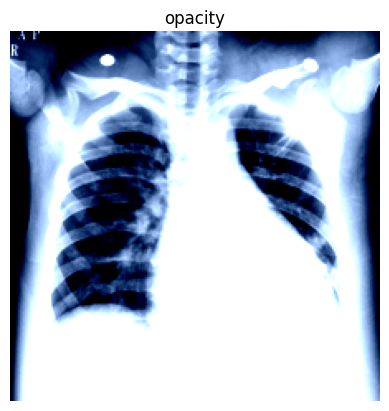

In [12]:
import matplotlib.pyplot as plt

image = images[0]
image = image.permute(1,2,0)

plt.imshow(image)
plt.title(train_dataset.classes[labels[0]])
plt.axis('off')
plt.show()

In [13]:
import torch
import torch.nn as nn

class MyNN(nn.Module):
    def __init__(self, input_channels=3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(input_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2,2),     # 224 -> 112

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2,2),     # 112 -> 56

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2,2)      # 56 -> 28
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(128 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(64, 2)       # normal and opacity
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [19]:
learning_rate = 0.001
epochs = 10

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = MyNN(3)# gray scale image for tHat reason i apply 1 if here RGB images than i apply 3
model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
    weight_decay=1e-4
)

In [20]:
# training loop

for epoch in range(epochs):

  total_epoch_loss = 0

  for batch_features, batch_labels in train_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    # forward pass
    outputs = model(batch_features)

    # calculate loss
    loss = criterion(outputs, batch_labels)

    # back pass
    optimizer.zero_grad()
    loss.backward()

    # update grads
    optimizer.step()

    total_epoch_loss = total_epoch_loss + loss.item()

  avg_loss = total_epoch_loss/len(train_loader)
  print(f'Epoch: {epoch + 1} , Loss: {avg_loss}')

Epoch: 1 , Loss: 0.5699545226601773
Epoch: 2 , Loss: 0.2015232926877126
Epoch: 3 , Loss: 0.11646951447283545
Epoch: 4 , Loss: 0.06839794672850985
Epoch: 5 , Loss: 0.06912778897488508
Epoch: 6 , Loss: 0.06803565071130344
Epoch: 7 , Loss: 0.05050306444502439
Epoch: 8 , Loss: 0.044255319577460414
Epoch: 9 , Loss: 0.04305927017346151
Epoch: 10 , Loss: 0.025365640714321323


In [16]:
for epoch in range(epochs):

    total_epoch_loss = 0

    model.train()

    for batch_features, batch_labels in train_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        # Forward Pass
        outputs = model(batch_features)

        # Loss
        loss = criterion(outputs, batch_labels)

        # Backward Pass
        optimizer.zero_grad()
        loss.backward()

        # Update Weights
        optimizer.step()

        total_epoch_loss += loss.item()

    avg_loss = total_epoch_loss / len(train_loader)

    print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}')

Epoch [1/1], Loss: 0.1435


In [17]:

model.eval()


MyNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p

In [21]:

# evaluation on test data
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in test_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.6762820512820513
